# 02 - Data Cleaning and Exploratory Data Analysis (EDA)

**Objective:** Clean the dataset with justified decisions, describe it with statistics, and use plots to discover which variables relate to `charges` - and which patterns could trip up a linear model.

**Role in the ML workflow:** *Pandas and EDA* (inspect, clean, understand) + *Visualization* (find distributions, relationships, patterns and problems). Findings here drive the feature engineering in notebook 03.

### Concepts to understand first
* **Skewness:** a measure of asymmetry. `0` = symmetric; positive = long tail to the right (a few very large values). Rule of thumb: |skew| > 1 is strongly skewed.
* **Quartiles and IQR:** Q1 / Q3 are the 25th / 75th percentiles; `IQR = Q3 - Q1` is the spread of the middle 50%. The common *outlier rule* flags values beyond `Q1 - 1.5*IQR` or `Q3 + 1.5*IQR`. A flagged value is "unusual", **not** automatically "wrong".
* **Correlation vs causation:** a correlation coefficient measures how closely two variables move together in a straight-line way. It never proves that one *causes* the other.

## Setup

In [1]:
import sys
import warnings
from pathlib import Path

# Make the project root importable so we can use the code in src/.
# (Jupyter's working directory is notebooks/, so the project root is one level up.)
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_preprocessing import (
    load_raw_data, clean_data, CLEAN_DATA_PATH, FIGURES_DIR, TARGET,
)

sns.set_theme(style="whitegrid", context="notebook")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    """Save the current figure into reports/figures/ (used later in the README)."""
    plt.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

raw = load_raw_data()
print("Raw shape:", raw.shape)

Raw shape: (1338, 7)


## Part A - Data cleaning

Inspect first, transform later. Every decision below is justified.

### A1. Missing values, data types, invalid values

In [3]:
print("Missing values:", int(raw.isna().sum().sum()))
print()
print(raw.dtypes)
print()
print("Impossible values (age<=0, bmi<=0, children<0, charges<=0):",
      int(((raw.age <= 0) | (raw.bmi <= 0) | (raw.children < 0) | (raw[TARGET] <= 0)).sum()))

Missing values: 0

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

Impossible values (age<=0, bmi<=0, children<0, charges<=0): 0


No missing values, correct data types, and no impossible values (as already seen in notebook 01), so no imputation or type conversion is needed.

### A2. Duplicates - remove or keep?

In [4]:
dupes = raw[raw.duplicated(keep=False)]
print("Rows involved in duplication:", len(dupes))
dupes

Rows involved in duplication: 2


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


**Decision: remove the second copy (keep one).**

*Why:*
1. All seven fields match, including `charges` to four decimal places. Two *different* people sharing identical continuous charges is very unlikely, so this is most probably one record entered twice.
2. A duplicated row would be counted twice in the statistics, and, more importantly, one copy could land in the training set and the other in the test set. The model would then be "tested" on a row it has already seen - a subtle form of **data leakage** that makes test scores look slightly better than they are.
3. The effect on results is tiny (1 row out of 1,338), so the choice is low-risk either way. We still prefer the safer option.

We cannot be 100% certain it is an error, so this reasoning is stated openly instead of hidden.

In [5]:
df = clean_data(raw)   # same function the training script uses -> consistent everywhere
print("Rows before:", len(raw), "| after:", len(df), "| removed:", len(raw) - len(df))

CLEAN_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(CLEAN_DATA_PATH, index=False)
print("Saved cleaned data to", CLEAN_DATA_PATH.relative_to(PROJECT_ROOT))

Rows before: 1338 | after: 1337 | removed: 1
Saved cleaned data to data/processed/insurance_clean.csv


### A3. Extreme values - remove or keep?

In [6]:
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return (series < low) | (series > high), low, high

for col in ["age", "bmi", "charges"]:
    mask, low, high = iqr_outliers(df[col])
    print(f"{col:8s} fence = [{low:10.1f}, {high:10.1f}]  flagged = {int(mask.sum()):3d}")

age      fence = [      -9.0,       87.0]  flagged =   0
bmi      fence = [      13.7,       47.3]  flagged =   9
charges  fence = [  -13120.7,    34524.8]  flagged = 139


In [7]:
# Who are the 'outlier' charges?
mask, low, high = iqr_outliers(df["charges"])
flagged = df[mask]
print("Flagged charges:", len(flagged))
print("Share who are smokers:", round((flagged["smoker"] == "yes").mean(), 3))
print("Share of the smokers among them with BMI >= 30:",
      round((flagged.loc[flagged["smoker"] == "yes", "bmi"] >= 30).mean(), 3))

Flagged charges: 139
Share who are smokers: 0.978
Share of the smokers among them with BMI >= 30: 0.971


**Decision: keep all extreme observations.**

The IQR rule flags 139 high charges, but almost all (136) are **smokers**, and nearly all of those smokers have a BMI of 30 or more. These are not mistakes - they are a real, explainable group of high-cost people, and an insurance model must learn about them. Deleting them would make the model blind to exactly the cases that matter most financially. The 9 high-BMI values are plausible measurements too.

*If extreme values hurt a model, it is better to change the model or features (e.g. add a smoker-BMI interaction) than to delete real data.*

## Part B - Descriptive statistics

In [8]:
numeric = ["age", "bmi", "children", "charges"]
stats = pd.DataFrame({
    "mean":   df[numeric].mean(),
    "median": df[numeric].median(),
    "std":    df[numeric].std(),
    "min":    df[numeric].min(),
    "Q1":     df[numeric].quantile(0.25),
    "Q3":     df[numeric].quantile(0.75),
    "max":    df[numeric].max(),
})
stats["IQR"] = stats["Q3"] - stats["Q1"]
stats["skewness"] = df[numeric].skew()
stats.round(2)

,mean,median,std,min,Q1,Q3,max,IQR,skewness
age,39.22,39.00,14.04,18.00,27.00,51.00,64.00,24.00,0.05
bmi,30.66,30.40,6.10,15.96,26.29,34.70,53.13,8.41,0.28
children,1.10,1.00,1.21,0.00,0.00,2.00,5.00,2.00,0.94
charges,13279.12,9386.16,12110.36,1121.87,4746.34,16657.72,63770.43,11911.37,1.52


**What the statistics reveal**
* **`age`:** mean 39.2 vs median 39, skewness about 0.05 - symmetric, spread evenly between 18 and 64.
* **`bmi`:** mean 30.7 vs median 30.4, skewness 0.28 - close to symmetric (mild right tail). The *typical* person in this dataset has a BMI in the "obese" range (>= 30).
* **`children`:** median 1, skewness 0.94 - most people have few dependants (43% have none).
* **`charges`:** mean (about 13,279) is well above the median (about 9,386) and skewness is **1.52** - strongly right-skewed. A few very expensive cases pull the mean up. Its standard deviation (about 12,110) is almost as large as the mean, so predicting with the mean alone would be very inaccurate. This is the key challenge of the project.

## Part C - Visualizations

### 1-3. Distributions: age, BMI and charges

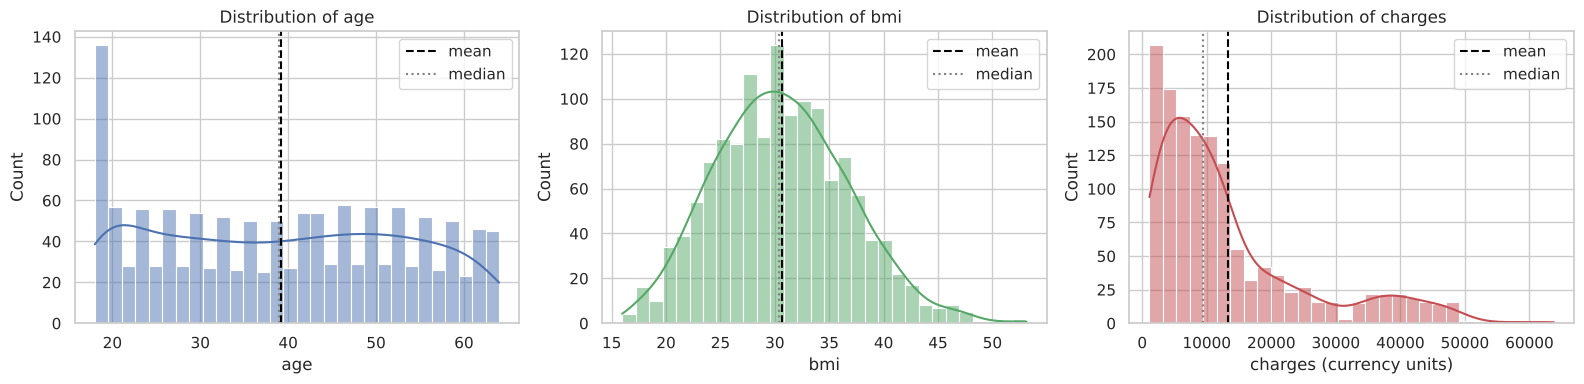

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, color in zip(axes, ["age", "bmi", "charges"], ["#4C72B0", "#55A868", "#C44E52"]):
    sns.histplot(df[col], kde=True, bins=30, color=color, ax=ax)
    ax.axvline(df[col].mean(), color="black", linestyle="--", label="mean")
    ax.axvline(df[col].median(), color="gray", linestyle=":", label="median")
    ax.set_title(f"Distribution of {col}")
    ax.legend()
axes[2].set_xlabel("charges (currency units)")
plt.tight_layout()
save_fig("01_distributions_age_bmi_charges")
plt.show()

* **Age:** roughly uniform, with a noticeable spike at ages 18-19 (136 people, versus about 27 per year of age elsewhere). That is a quirk of how the data was sampled, not an error.
* **BMI:** bell-shaped and centred near 30; mean and median almost coincide.
* **Charges:** a tall peak at low values and a long right tail; the mean (dashed) sits to the right of the median (dotted). Strong right skew confirmed.

Skewness of charges      : 1.52
Skewness of log(charges) : -0.09


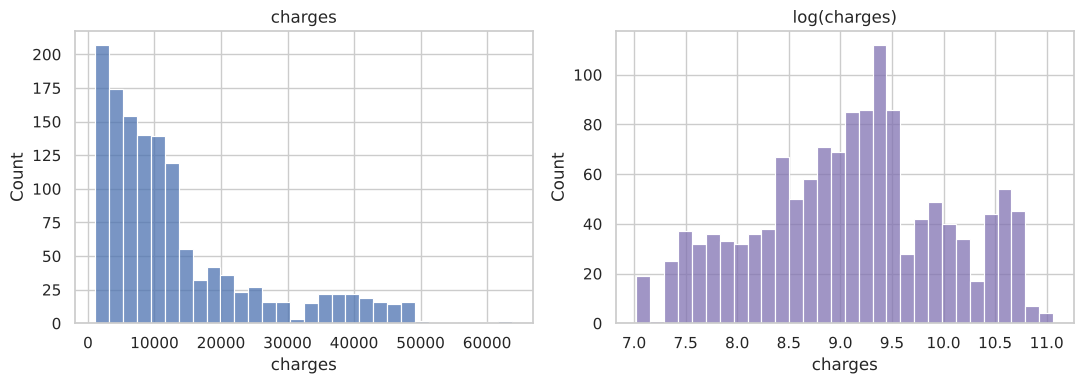

In [10]:
# Does a log transform remove the skew? (a common remedy for money-like variables)
print("Skewness of charges      :", round(df["charges"].skew(), 2))
print("Skewness of log(charges) :", round(np.log(df["charges"]).skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["charges"], bins=30, ax=axes[0]); axes[0].set_title("charges")
sns.histplot(np.log(df["charges"]), bins=30, ax=axes[1], color="#8172B2"); axes[1].set_title("log(charges)")
plt.tight_layout(); plt.show()

Taking the log makes the distribution nearly symmetric (skew about -0.09). We note this as a possible future improvement (modelling `log(charges)`), but the project specification asks us to model `charges` directly, so we keep the target as it is and look at its effect in the residual analysis.

### 4. Boxplots of the numerical variables

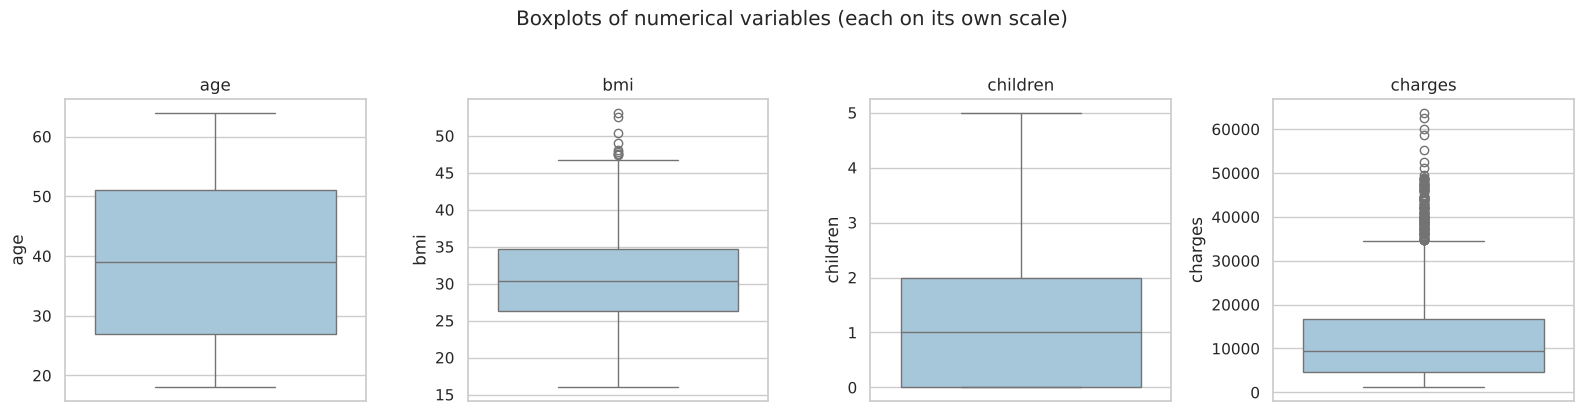

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ["age", "bmi", "children", "charges"]):
    sns.boxplot(y=df[col], ax=ax, color="#9ecae1")
    ax.set_title(col)
plt.suptitle("Boxplots of numerical variables (each on its own scale)", y=1.03)
plt.tight_layout()
save_fig("02_boxplots_numerical")
plt.show()

`age` has no outliers; `bmi` has a few high points; `children` has a handful above 4; `charges` has many high points (the 139 smokers-dominated cases discussed above). Each plot has its own y-scale because the variables are in different units.

### 5. Charges by smoking status

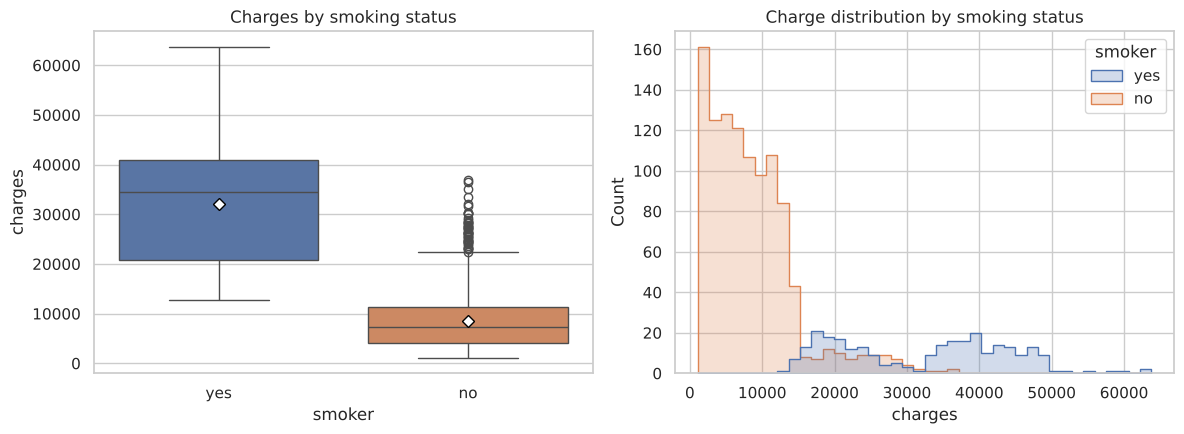

,count,mean,median,std
smoker,,,,
no,1063,8441.0,7346.0,5993.0
yes,274,32050.0,34456.0,11542.0


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=df, x="smoker", y="charges", hue="smoker", legend=False, ax=axes[0], showmeans=True,
            meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black"})
axes[0].set_title("Charges by smoking status")
sns.histplot(data=df, x="charges", hue="smoker", bins=40, ax=axes[1], element="step")
axes[1].set_title("Charge distribution by smoking status")
plt.tight_layout()
save_fig("03_charges_by_smoker")
plt.show()

df.groupby("smoker")["charges"].agg(["count", "mean", "median", "std"]).round(0)

**Smokers have much higher charges:** mean about 32,050 vs 8,441 for non-smokers (roughly 3.8 times as much), median 34,456 vs 7,346. The two distributions barely overlap. The right skew of `charges` is largely a *mixture* of two groups: the big left hump is non-smokers, and the smaller, higher hump is smokers. **Smoking status is the single most important feature.**

*Caution:* this shows a strong association in this data. It does not by itself prove the mechanism or the size of the causal effect.

### 6-8. Charges by sex, region and number of children

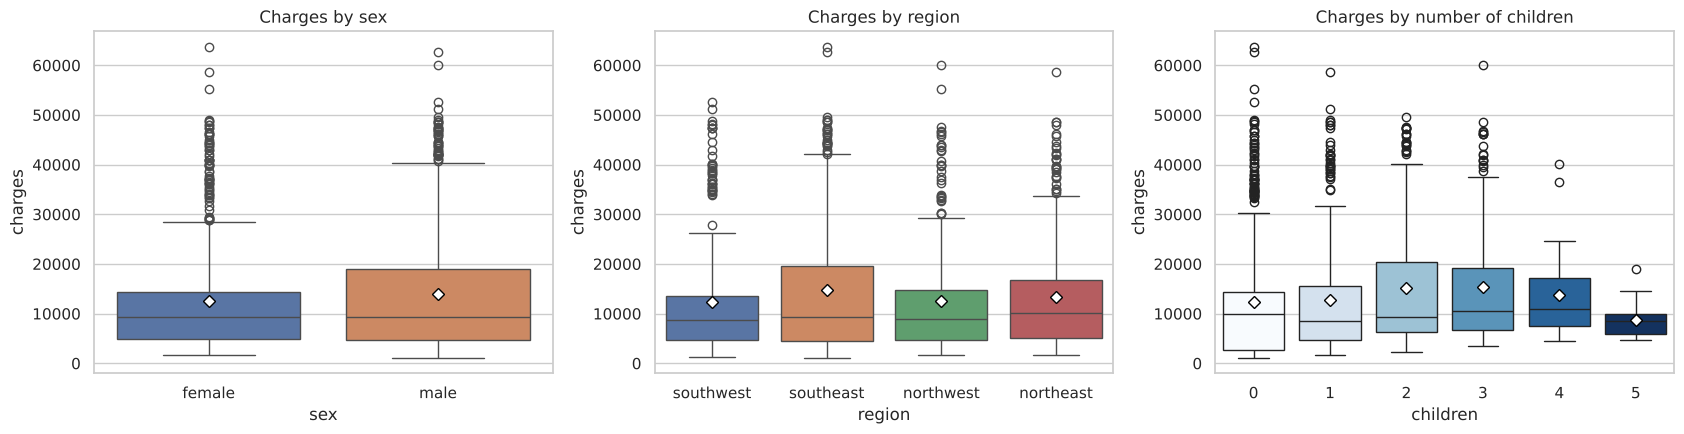

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(data=df, x="sex", y="charges", hue="sex", legend=False, ax=axes[0], showmeans=True,
            meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black"})
axes[0].set_title("Charges by sex")
sns.boxplot(data=df, x="region", y="charges", hue="region", legend=False, ax=axes[1], showmeans=True,
            meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black"})
axes[1].set_title("Charges by region")
sns.boxplot(data=df, x="children", y="charges", hue="children", legend=False, ax=axes[2], showmeans=True,
            palette="Blues", meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black"})
axes[2].set_title("Charges by number of children")
plt.tight_layout()
save_fig("04_charges_by_sex_region_children")
plt.show()

In [14]:
for col in ["sex", "region", "children"]:
    print(df.groupby(col)["charges"].agg(["count", "mean", "median"]).round(0), "\n")

        count     mean  median
sex                           
female    662  12570.0  9413.0
male      675  13975.0  9378.0 

           count     mean   median
region                            
northeast    324  13406.0  10058.0
northwest    324  12451.0   8977.0
southeast    364  14735.0   9294.0
southwest    325  12347.0   8799.0 

          count     mean   median
children                         
0           573  12385.0   9863.0
1           324  12731.0   8484.0
2           240  15074.0   9265.0
3           157  15355.0  10601.0
4            25  13851.0  11034.0
5            18   8786.0   8590.0 



* **Sex:** mean charges are higher for men (about 13,975 vs 12,570) but the **medians are almost identical** (about 9,378 vs 9,413). The gap in the mean comes from the high-charge tail; men are more often smokers in this data (about 24% vs 17%). So the raw sex difference is probably mostly a smoking difference - a case of *confounding*.
* **Region:** southeast has the highest mean (about 14,735), but medians are similar across regions (about 8,800-10,100) and the boxes overlap heavily. The southeast also has the highest average BMI (about 33.4 vs 29-30.6 elsewhere), so again other variables may explain part of the gap. Region looks like a weak predictor.
* **Children:** mean charges rise from 0 to 3 children (about 12,385 to 15,355) and then fall for 4 and 5 children - but those groups are tiny (25 and 18 people), so those means are noisy. The relationship is weak and not clearly linear.

### 9-10. Age and BMI versus charges (coloured by smoking status)

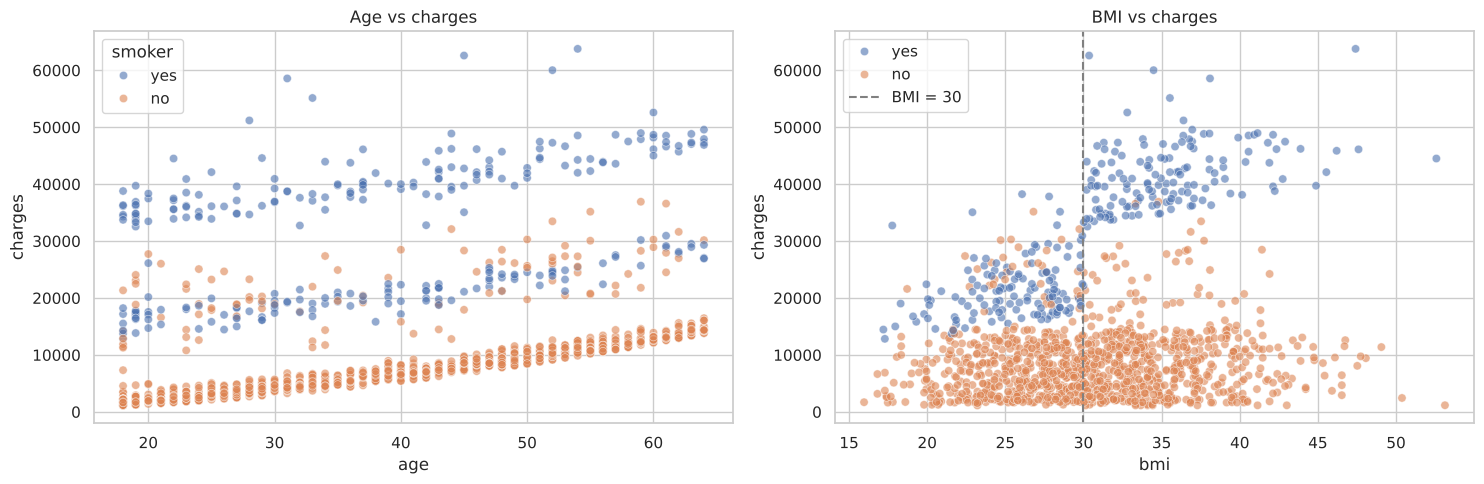

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=df, x="age", y="charges", hue="smoker", alpha=0.6, ax=axes[0])
axes[0].set_title("Age vs charges")
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", alpha=0.6, ax=axes[1])
axes[1].axvline(30, color="gray", linestyle="--", label="BMI = 30")
axes[1].legend()
axes[1].set_title("BMI vs charges")
plt.tight_layout()
save_fig("05_age_bmi_vs_charges")
plt.show()

**Age vs charges:** charges increase with age, and the points form roughly **three parallel upward bands**: a lower band (mostly non-smokers), a middle band, and an upper band (smokers). So the age relationship looks *roughly linear within each group*, but the groups sit at very different levels. A single straight line through all the points will fit poorly - the model needs to know who smokes.

**BMI vs charges:** for non-smokers there is almost no visible trend. For smokers, charges **jump sharply once BMI passes about 30** and keep rising with BMI. In other words, BMI matters mainly for smokers - an **interaction** between `smoker` and `bmi`. A plain linear model with one BMI coefficient cannot represent this, which is the motivation for the engineered features in notebook 03.

### 11. Correlation heatmap

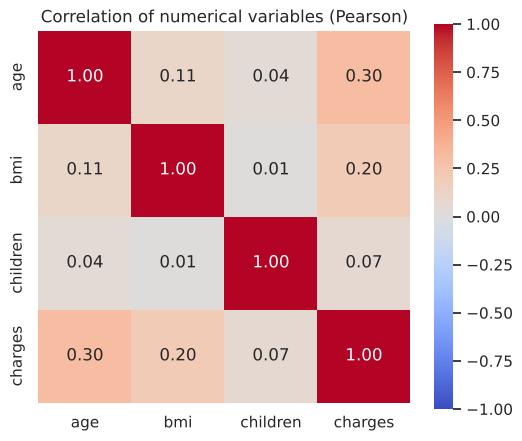

In [16]:
corr = df[["age", "bmi", "children", "charges"]].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation of numerical variables (Pearson)")
save_fig("06_correlation_heatmap")
plt.show()

Pooled correlations with `charges`: age 0.30, bmi 0.20, children 0.07. The predictors are almost uncorrelated with each other (e.g. age-bmi 0.11), so multicollinearity is not a concern.

**These pooled numbers understate the real structure**, because they ignore smoking. Splitting by smoker shows it:

In [17]:
print("Correlation with charges, by smoking status:")
print(df.groupby("smoker")[["age", "bmi", "children"]].corrwith(df["charges"]).round(2))

Correlation with charges, by smoking status:
         age   bmi  children
smoker                      
no      0.63  0.08      0.14
yes     0.37  0.81      0.04


/tmp/ipykernel_510/1139958743.py:2: Pandas4Warning: DataFrameGroupBy.corrwith is deprecated
  print(df.groupby("smoker")[["age", "bmi", "children"]].corrwith(df["charges"]).round(2))


* Non-smokers: age 0.63, bmi only 0.08.
* Smokers: age 0.37, **bmi 0.81**.

BMI is strongly related to charges *among smokers* but barely among non-smokers - exactly the interaction seen in the scatterplot. (This is still correlation, not proof of causation.)

### Smoking x obesity: a quick numeric check

In [18]:
df["obese"] = df["bmi"] >= 30
df.groupby(["smoker", "obese"])["charges"].agg(["count", "mean", "median"]).round(0)

count     mean   median
smoker obese                         
no     False    502   7977.0   6762.0
       True     561   8856.0   8084.0
yes    False    129  21363.0  20167.0
       True     145  41558.0  40904.0

Non-obese vs obese non-smokers differ little (mean about 7,977 vs 8,856). Among smokers, obesity roughly **doubles** the average charge (about 21,363 vs 41,558). This is the strongest single pattern in the data and a prime candidate for an engineered feature. We will *test* whether it helps - not assume it.

## Answers to the questions asked in the project brief

| Question | Answer from this EDA |
|---|---|
| Are charges skewed? | Yes, strongly right-skewed (skewness 1.52); log(charges) is nearly symmetric. |
| Do smokers have higher charges? | Yes - about 3.8x higher on average, with little overlap. |
| Does age vs charges look linear? | Roughly linear *within* groups (three bands), but a single pooled line misses the smoker/non-smoker gap. |
| Which variables look important? | smoker (strongest), age, and BMI *for smokers*. Sex, region and children look weak. |
| Does correlation prove causation? | No. These are associations in one observational sample. |

## Common errors and fixes
| Error | Cause | Fix |
|---|---|---|
| Seaborn warning about `palette` without `hue` | newer seaborn versions | pass `hue=` the same column and `legend=False` (done above) |
| Figures not saved | `reports/figures` missing | the setup cell creates it; run the setup cell first |
| `KeyError: 'obese'` later | the helper column was only created in this notebook | it is not used elsewhere; recreate it if needed |

## Practical task
1. Make a scatter plot of `bmi` vs `charges` for **non-smokers only** and describe the trend.
2. Compute the median `charges` for each `age` decade (hint: `pd.cut`).
3. Write two sentences explaining why the sex difference in mean charges should not be reported as "men cost more because they are men".

**Next:** notebook 03 - feature engineering.